# Projeto 2
### Pergunta Norteadora: quais são os jogadores mais superfaturados da NBA?

---

### Definição: o que é um jogador superfaturado?

Neste trabalho, um **jogador superfaturado** é aquele cujo **salário é maior do que o seu desempenho em quadra justificaria**.

Premissa simples: **o salário deveria acompanhar o desempenho**.

- Jogador com **desempenho alto** → deveria ter **salário alto**.
- Jogador com **desempenho baixo** → deveria ter **salário baixo**.


---

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

### Funções utilitárias

In [4]:
from matplotlib.ticker import MaxNLocator, FuncFormatter, LogLocator


def _numero_compacto(x, pos=None):
    """Rótulo curto para os eixos: 15000 → 15k, 20000000 → 20M, 1990 → 1990, 0.25 → 0.25."""
    if abs(x) >= 1e6:
        return f"{x / 1e6:g}M"
    if abs(x) >= 1e4:
        return f"{x / 1e3:g}k"
    return f"{x:g}"

def plt_histograms(dataset,
                   title="Histogramas",
                   colunas_irrelevantes=None,
                   n_cols=6,
                   bins=30,
                   max_valores_inteiros=100,
                   salvar_em=None):
    """
    Plota um histograma para cada coluna numérica de qualquer DataFrame, em grade.

    dataset              : DataFrame
    title                : título geral da figura
    colunas_irrelevantes : colunas a ignorar (ex.: IDs)
    n_cols               : nº de histogramas por linha
    bins                 : nº aproximado de barras de cada histograma
    max_valores_inteiros : colunas só com inteiros e amplitude até esse valor (anos, jogos, experiência)
                           ganham UMA barra por valor, centrada no número
    salvar_em            : caminho para salvar a figura (ex.: "histogramas.png"); None = não salva
    """
    ignorar = set(colunas_irrelevantes or [])
    colunas_numericas = [c for c in dataset.select_dtypes(include=np.number).columns if c not in ignorar]

    if not colunas_numericas:
        print("Nenhuma coluna numérica para plotar.")
        return

    n_cols = min(n_cols, len(colunas_numericas))
    n_linhas = int(np.ceil(len(colunas_numericas) / n_cols))

    # layout="constrained" reserva espaço para o suptitle (o tight_layout o ignora e ele sobrepõe a 1ª linha)
    fig, axes = plt.subplots(n_linhas, n_cols, figsize=(4 * n_cols, 3 * n_linhas),
                             squeeze=False, layout="constrained")
    axes = axes.flatten()

    for ax, coluna in zip(axes, colunas_numericas):
        valores = dataset[coluna].dropna()
        if valores.empty:
            ax.set_title(coluna, fontsize=10)
            continue

        minimo, maximo = valores.min(), valores.max()
        so_inteiros = bool(np.all(np.mod(valores, 1) == 0))

        if so_inteiros:
            # Dados discretos: barras de largura inteira com bordas em x.5 → cada barra contém
            # sempre o mesmo nº de valores possíveis (sem barras falsamente altas ou vazias)
            amplitude = maximo - minimo + 1
            largura = 1 if amplitude <= max_valores_inteiros else int(np.ceil(amplitude / bins))
            bordas = np.arange(minimo - 0.5, maximo + largura + 0.5, largura)
            ax.xaxis.set_major_locator(MaxNLocator(nbins=6, integer=True))
        else:
            bordas = bins
            ax.xaxis.set_major_locator(MaxNLocator(nbins=5))

        ax.hist(valores, bins=bordas, color="steelblue", edgecolor="black", linewidth=0.5)
        ax.set_title(coluna, fontsize=10)

        # rótulos curtos (15k, 20M) → sem números encavalados nem "1e7" no canto do eixo
        ax.xaxis.set_major_formatter(FuncFormatter(_numero_compacto))
        ax.yaxis.set_major_formatter(FuncFormatter(_numero_compacto))
        ax.tick_params(labelsize=8)

    # desliga os eixos que sobraram na grade
    for ax in axes[len(colunas_numericas):]:
        ax.axis("off")

    fig.suptitle(title, fontsize=16)
    if salvar_em:
        fig.savefig(salvar_em, dpi=150)
    plt.show()

def plt_correlacao_com_alvo(dataset,
                            target,
                            title=None,
                            colunas_irrelevantes=None,
                            rotulo="População",
                            metodo="pearson",
                            top=None):
    """
    Mesmo design de plt_multi_correlacoes, mas com UMA coluna: cada linha é uma variável numérica
    e a célula é a correlação dela com `target`. Ordenada da maior para a menor.

    dataset              : DataFrame
    target               : coluna de referência (ex.: "SALARY")
    colunas_irrelevantes : colunas a ignorar (ex.: IDs)
    rotulo               : nome da coluna no topo da figura
    metodo               : "pearson", "spearman" ou "kendall"
    top                  : se informado, mostra só as `top` correlações mais fortes (em valor absoluto)

    Retorna a Series de correlações (ordenada).
    """
    ignorar = set(colunas_irrelevantes or []) | {target}
    colunas_numericas = [c for c in dataset.select_dtypes(include=np.number).columns if c not in ignorar]

    corr = dataset[colunas_numericas].corrwith(dataset[target], method=metodo).dropna()
    if top is not None:
        corr = corr.loc[corr.abs().sort_values(ascending=False).index[:top]]
    corr = corr.sort_values(ascending=False)  # maior em cima

    matriz_correlacao = corr.to_frame(rotulo)
    rotulos_colunas = list(matriz_correlacao.columns)

    fig, ax = plt.subplots(figsize=(1.6 * len(rotulos_colunas) + 3, 0.4 * len(matriz_correlacao.index) + 2))

    im = ax.imshow(matriz_correlacao, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
    fig.colorbar(im, ax=ax, label="Correlação")

    for i in range(len(matriz_correlacao.index)):
        for j in range(len(matriz_correlacao.columns)):
            ax.text(
                j, i,
                f"{matriz_correlacao.iloc[i, j]:.2f}",
                ha="center", va="center",
                color="#003300", fontweight="bold", fontsize=8
            )

    ax.set_xticks(range(len(rotulos_colunas)))
    ax.set_xticklabels(rotulos_colunas, rotation=45, ha="left")
    ax.xaxis.set_ticks_position("top")
    ax.xaxis.set_label_position("top")

    ax.set_yticks(range(len(matriz_correlacao.index)))
    ax.set_yticklabels(matriz_correlacao.index)

    ax.set_title(title or f"Correlação de cada variável com {target}", pad=30)
    plt.tight_layout()
    plt.show()

    return corr

def _moda(valores):
    """Valor mais frequente; NaN se nenhum valor se repete (aí não existe moda de fato)."""
    contagem = valores.value_counts()
    if contagem.empty or contagem.iloc[0] < 2:
        return np.nan
    return contagem.index[0]

def plt_scatter(dataset,
                x,
                y,
                title=None,
                xlabel=None,
                ylabel=None,
                log_y=True,
                jitter=0.0,
                linhas=("media", "mediana", "moda"),
                min_pontos=5,
                salvar_em=None):
    """
    Gráfico de dispersão de y × x, com linhas de média, mediana e moda de y para cada valor de x.

    dataset    : DataFrame
    x, y       : nomes das colunas dos eixos
    title      : título do gráfico (padrão: "y × x")
    xlabel     : rótulo do eixo x (padrão: nome da coluna x)
    ylabel     : rótulo do eixo y (padrão: nome da coluna y)
    log_y      : eixo y em escala log, com marcadores em 1, 2, 3 e 5 de cada potência de 10
    jitter     : deslocamento aleatório no x (ex.: 0.3) para espalhar pontos quando x é inteiro (anos, jogos)
    linhas     : estatísticas de y a desenhar para cada valor de x: "media", "mediana", "moda"
    min_pontos : só desenha as linhas nos valores de x com pelo menos esse nº de pontos (evita linhas ruidosas)
    salvar_em  : caminho para salvar a figura (ex.: "scatter.png"); None = não salva
    """
    dados = dataset[[x, y]].dropna()
    if log_y:
        dados = dados[dados[y] > 0]   # log não aceita zero nem negativos

    fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")

    # pontos pequenos e transparentes: com milhares de pontos, mostra onde há concentração
    deslocamento = np.random.default_rng(42).uniform(-jitter, jitter, len(dados)) if jitter else 0
    ax.scatter(dados[x] + deslocamento, dados[y], s=4, alpha=0.3, color="steelblue", label="Observações")

    # estatísticas de y para cada valor de x
    grupos = dados.groupby(x)[y]
    validos = grupos.size() >= min_pontos
    estatisticas = {"media": ("Média", grupos.mean(), "red"),
                    "mediana": ("Mediana", grupos.median(), "black"),
                    "moda": ("Moda", grupos.agg(_moda), "darkorange")}
    for chave in linhas:
        nome, serie, cor = estatisticas[chave]
        serie = serie[validos]
        ax.plot(serie.index, serie.values, color=cor, linewidth=1.8, marker="o", markersize=3, label=nome)

    if log_y:
        ax.set_yscale("log")
        ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 3.0, 5.0)))
    ax.yaxis.set_major_formatter(FuncFormatter(_numero_compacto))   # 10k, 1M, ... em vez de 1e7
    ax.grid(axis="y", which="major", alpha=0.3)

    ax.set_xlabel(xlabel or x)
    ax.set_ylabel(ylabel or (f"{y} (escala log)" if log_y else y))
    ax.set_title(title or f"{y} × {x}")
    ax.legend(loc="lower right", markerscale=2)

    if salvar_em:
        fig.savefig(salvar_em, dpi=150)
    plt.show()


def plt_grid_heatmap(resultados,
                     modelo,
                     linha,
                     coluna,
                     title=None,
                     ax=None,
                     cmap="YlGnBu_r"):
    """
    Grade de hiperparâmetros de um modelo do GridSearchCV: cada célula é uma combinação,
    com o erro médio de treino (Tr) e de validação (Val). A cor é o erro de validação (escuro = menor).

    resultados : DataFrame do grid.cv_results_ com as colunas "Modelo" e "Hiperparâmetros"
                 (o GridSearchCV precisa de return_train_score=True)
    modelo     : nome da coluna "Modelo" (ou lista de nomes) a mostrar
    linha      : campo das linhas: hiperparâmetro (ex.: "alpha"), coluna de `resultados` (ex.: "Pipeline")
                 ou lista deles (ex.: ["Pipeline", "degree"] = uma linha por combinação); None = uma linha só
    coluna     : campo das colunas (mesmas opções)
    title      : título (padrão: nome do modelo)
    ax         : eixo onde desenhar (None = cria uma figura)
    cmap       : mapa de cores ("_r" = invertido: erro menor fica escuro)

    Se outros hiperparâmetros variam além de linha e coluna, cada célula mostra a melhor combinação deles.
    """
    nomes = [modelo] if isinstance(modelo, str) else list(modelo)
    df = resultados[resultados["Modelo"].isin(nomes)].copy()
    campos_lin = [] if linha is None else [linha] if isinstance(linha, str) else list(linha)
    campos_col = [coluna] if isinstance(coluna, str) else list(coluna)
    colunas_df = set(df.columns)

    def extrair(campos):
        """Tupla com os valores dos campos em cada linha. dtype=object preserva o None (ex.: max_depth=None)."""
        partes = [df[c].tolist() if c in colunas_df else [h.get(c) for h in df["Hiperparâmetros"]] for c in campos]
        return pd.Series(list(zip(*partes)) if partes else [()] * len(df), index=df.index, dtype=object)

    def rotulo(campos, valores):
        return " | ".join(str(v) if c in colunas_df else f"{c}={v}" for c, v in zip(campos, valores))

    df["_lin"] = extrair(campos_lin)
    df["_col"] = extrair(campos_col)
    df["_tr"] = -df["mean_train_score"]
    df["_val"] = -df["mean_test_score"]
    df = df.sort_values("_val").drop_duplicates(["_lin", "_col"])   # melhor combinação por célula

    def ordenar(valores):
        return sorted(valores, key=lambda t: tuple((v is None, 0 if v is None else v) for v in t))   # None por último

    linhas, colunas = ordenar(df["_lin"].unique()), ordenar(df["_col"].unique())
    tr = np.full((len(linhas), len(colunas)), np.nan)
    val = np.full_like(tr, np.nan)
    for _, r in df.iterrows():
        i, j = linhas.index(r["_lin"]), colunas.index(r["_col"])
        tr[i, j], val[i, j] = r["_tr"], r["_val"]

    criou_figura = ax is None
    if criou_figura:
        fig, ax = plt.subplots(figsize=(2.6 * len(colunas) + 2, 1.3 * len(linhas) + 1.5), layout="constrained")

    im = ax.imshow(val, cmap=cmap, aspect="auto")
    cbar = ax.figure.colorbar(im, ax=ax, label="RMSE validação (US$)")
    cbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{v:.0f}"))   # número bruto, sem "M"

    minimo = np.nanmin(val)
    for i in range(len(linhas)):
        for j in range(len(colunas)):
            if np.isnan(val[i, j]):
                continue
            r, g, b, _ = im.cmap(im.norm(val[i, j]))          # cor da célula → texto claro em fundo escuro
            fundo_escuro = 0.299 * r + 0.587 * g + 0.114 * b < 0.5
            ax.text(j, i, f"Tr: {abs(tr[i, j]):.0f}\nVal: {val[i, j]:.0f}",
                    ha="center", va="center", fontsize=9,
                    color="white" if fundo_escuro else "black",
                    fontweight="bold" if val[i, j] == minimo else "normal")   # destaca a melhor

    ax.set_xticks(range(len(colunas)))
    ax.set_xticklabels([rotulo(campos_col, c) for c in colunas], fontsize=8)
    ax.set_yticks(range(len(linhas)))
    ax.set_yticklabels([rotulo(campos_lin, l) for l in linhas], fontsize=8)
    ax.set_title(title or ", ".join(nomes), fontsize=11)

    if criou_figura:
        plt.show()


from sklearn.model_selection import learning_curve


def plt_learning_curve(model,
                       X,
                       y,
                       cv=5,
                       title=None,
                       ax=None,
                       train_sizes=np.linspace(0.1, 1.0, 10),
                       n_jobs=None):
    """
    Curva de aprendizado (como na a13): RMSE de treino e de validação conforme o conjunto de treino cresce.
    Linhas = média entre os folds; faixas = média ± erro padrão.

    model       : estimador ou Pipeline (é clonado e treinado várias vezes; o original não muda)
    X, y        : atributos e rótulo (só o conjunto de treino)
    cv          : nº de folds ou lista de divisões (use o mesmo `cv` do Grid Search: estratificado e agrupado)
    title       : título do gráfico (padrão: nome da classe do modelo)
    ax          : eixo onde desenhar (None = cria uma figura)
    train_sizes : frações do conjunto de treino de cada fold a usar
    n_jobs      : nº de treinos em paralelo

    Retorna (tamanhos, erros_treino, erros_validacao), com os erros em US$ (uma coluna por fold).
    """
    tamanhos, train_scores, valid_scores = learning_curve(model, X, y,
                                                          train_sizes=train_sizes,
                                                          cv=cv,
                                                          scoring="neg_root_mean_squared_error",
                                                          shuffle=True,      # sem isso, as frações pequenas pegam
                                                          random_state=42,   # sempre as primeiras linhas (mesmos jogadores)
                                                          n_jobs=n_jobs)
    erros_treino, erros_validacao = -train_scores, -valid_scores   # neg_ → positivo (US$)

    criou_figura = ax is None
    if criou_figura:
        fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")

    for nome, erros, estilo, cor in [("Treino", erros_treino, "r-o", "red"),
                                     ("Validação", erros_validacao, "b-x", "blue")]:
        media = erros.mean(axis=1)
        erro_padrao = erros.std(axis=1, ddof=1) / np.sqrt(erros.shape[1])
        ax.plot(tamanhos, media, estilo, linewidth=2, label=nome)
        ax.fill_between(tamanhos, media - erro_padrao, media + erro_padrao, color=cor, alpha=0.2)

    ax.set_xlabel("Tamanho do conjunto de treino")
    ax.set_ylabel("RMSE (US$)")
    ax.xaxis.set_major_formatter(FuncFormatter(_numero_compacto))
    ax.yaxis.set_major_formatter(FuncFormatter(_numero_compacto))
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right")
    ax.set_title(title or type(model).__name__, fontsize=10)

    if criou_figura:
        plt.show()
    return tamanhos, erros_treino, erros_validacao


### Personalização do dataset

#### Salário × estatísticas

- **Salário** → `PLAYER_ID` + `SEASON_ID`
- **Estatísticas** → `PLAYER_ID` + `SEASON_ID` + `SEASON_TYPE` + time (troca → linha por time + `TOT`)
- Trocas de time: só na `Regular Season`

In [5]:
stats = pd.read_csv("nba/career_stats_by_season_with_salary.csv")
bio = pd.read_csv("nba/players_bio.csv", usecols=["PERSON_ID", "POSITION"])

In [6]:
# Inconsistências da fonte: acertos > tentativas é impossível (erro de registro, ex.: playoffs dos anos 1940-50).
# Removidas ANTES de montar o players_stats, para não contaminarem os acumulados de carreira (TOT_*).
PARES_ACERTOS_TENTATIVAS = [("FGM", "FGA"), ("FG3M", "FG3A"), ("FTM", "FTA")]

inconsistente = pd.Series(False, index=stats.index)
for feitos, tentados in PARES_ACERTOS_TENTATIVAS:
    inconsistente |= stats[feitos] > stats[tentados]

print("Linhas inconsistentes removidas da fonte:", inconsistente.sum())
stats = stats[~inconsistente].reset_index(drop=True)

Linhas inconsistentes removidas da fonte: 25


In [7]:
CHAVE = ["PLAYER_ID", "SEASON_ID"]
CONTAGENS = ["GP", "GS", "MIN", "FGM", "FGA", "FG3M", "FG3A", "FTM", "FTA",
             "OREB", "DREB", "REB", "AST", "STL", "BLK", "TOV", "PF", "PTS"]
PERCENTUAIS = {"FG_PCT": ("FGM", "FGA"), "FG3_PCT": ("FG3M", "FG3A"), "FT_PCT": ("FTM", "FTA")}

# 1- Uma linha por jogador + temporada + tipo. -  Trocas de time só ocorrem na Regular Season: nesses casos fica só a linha TOT.
regular = stats[stats["SEASON_TYPE"] == "Regular Season"]


varios_times = regular.duplicated(CHAVE, keep=False)


regular = regular[~varios_times | (regular["TEAM_ABBREVIATION"] == "TOT")]
playoffs = stats[stats["SEASON_TYPE"] == "Playoffs"]

# 2- Base: uma linha por jogador + temporada, com o salário
base = stats.groupby(CHAVE, as_index=False)["SALARY"].first().sort_values(CHAVE)


def percentuais(df, prefixo):
    """ (acertos / tentativas)."""
    for pct, (feitos, tentados) in PERCENTUAIS.items():
        df[prefixo + pct] = (df[prefixo + feitos] / df[prefixo + tentados].replace(0, np.nan)).round(3)


def estatisticas(dados, prefixo, col_exp, zerar_sem_jogos=False):
    """
    Para um tipo de temporada, devolve:
      - {prefixo}*      : números SÓ daquela temporada
                          (se não jogou esse tipo no ano: 0 se zerar_sem_jogos=True, senão NaN)
      - TOT_{prefixo}*  : acumulado da carreira ANTES daquela temporada (só o passado)
      - col_exp         : nº de temporadas desse tipo disputadas até aquela temporada
    """
    t = base[CHAVE].merge(dados[CHAVE + CONTAGENS], on=CHAVE, how="left", indicator=True)
    jogador = t["PLAYER_ID"]
    jogou = t["_merge"] == "both"
    out = t[CHAVE].copy()

    # Experiência
    out[col_exp] = jogou.astype(int).groupby(jogador).cumsum()

    # Números da temporada
    for c in CONTAGENS:
        out[prefixo + c] = t[c]
    if zerar_sem_jogos:
        # Temporada sem jogos desse tipo -> 0 em todas as contagens
        # (só nas linhas em que não jogou; NaN de estatística não registrada na época continua NaN)
        cols = [prefixo + c for c in CONTAGENS]
        out.loc[~jogou, cols] = 0
    percentuais(out, prefixo)

    # Acumulado até a temporada (temporada sem jogos soma 0: o ffill repete o acumulado anterior)
    acum = pd.DataFrame({c: t.groupby(jogador)[c].cumsum().groupby(jogador).ffill() for c in CONTAGENS})
    # Antes da 1ª temporada desse tipo, o acumulado é 0
    acum.loc[out[col_exp] == 0] = acum.loc[out[col_exp] == 0].fillna(0)

    # Só o passadoa, 1ª temporada da carreira não tem passado → 0
    passado = acum.groupby(jogador).shift(1, fill_value=0)

    tot = "TOT_" + prefixo
    for c in CONTAGENS:
        out[tot + c] = passado[c]
    percentuais(out, tot)
    return out


# Ano sem jogos de um tipo (só playoffs, ou só regular season) -> estatísticas desse tipo = 0
rs = estatisticas(regular, "Regular_Season_", "Regular_Season_SEASON_EXP", zerar_sem_jogos=True)
po = estatisticas(playoffs, "PLAYOFFS_", "PLAYOFFS_SEASON_EXP", zerar_sem_jogos=True)

# 3- Junta tudo: POSITION (bio) + Regular Season + Playoffs + salário
players_stats = (base[CHAVE]
                 .merge(bio.rename(columns={"PERSON_ID": "PLAYER_ID"}), on="PLAYER_ID", how="left")
                 .merge(rs, on=CHAVE)
                 .merge(po, on=CHAVE)
                 .merge(base, on=CHAVE))

def bloco(prefixo):
    cols = []
    for c in CONTAGENS:
        cols.append(prefixo + c)
        cols += [prefixo + p for p, (_, tentados) in PERCENTUAIS.items() if tentados == c]
    return cols


players_stats = players_stats[CHAVE + ["POSITION", "Regular_Season_SEASON_EXP", "PLAYOFFS_SEASON_EXP"]
                              + bloco("Regular_Season_") + bloco("PLAYOFFS_")
                              + bloco("TOT_Regular_Season_") + bloco("TOT_PLAYOFFS_")
                              + ["SALARY"]]



# Remover temporadas sem salário, depois de calcular experiência e acumulados
players_stats = players_stats.dropna(subset=["SALARY"]).reset_index(drop=True)

# transformando SEASON_ID em inteiro - ano de início da temporada
players_stats["SEASON_ID"] = players_stats["SEASON_ID"].astype(str).str[:4].astype(int)

players_stats.to_csv("nba/players_stats_by_season_with_salary.csv", index=False)
print(players_stats.shape)

(15783, 90)


### corelações com salário

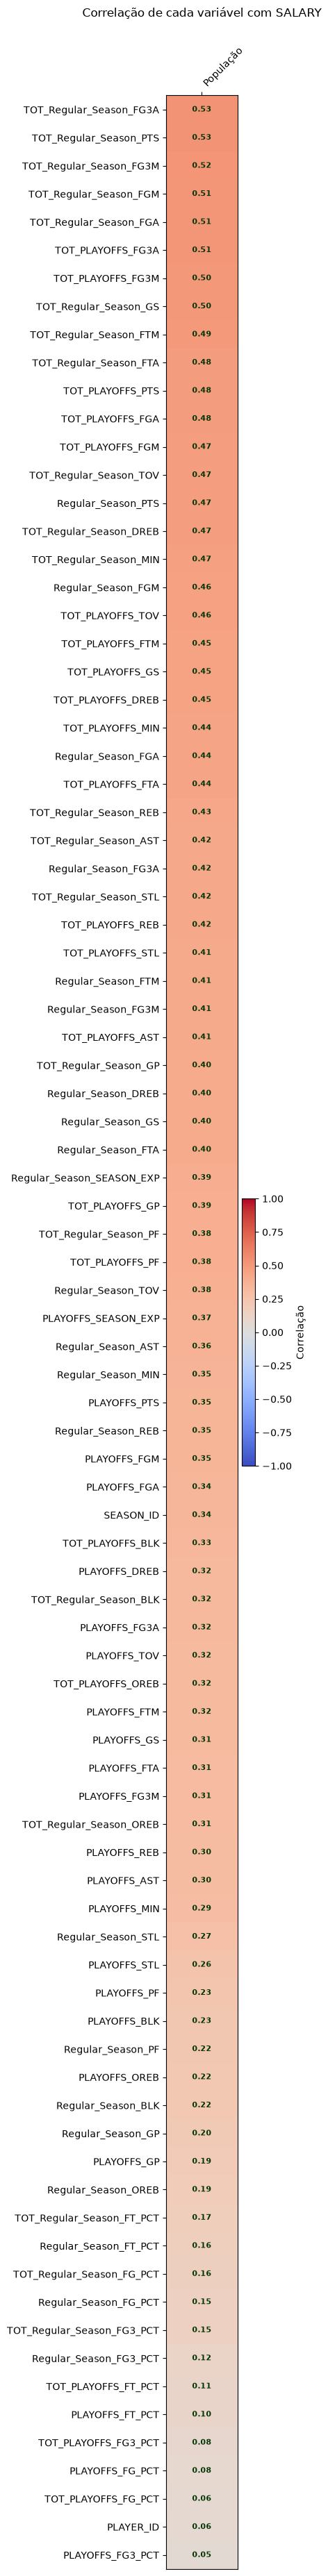

TOT_Regular_Season_FG3A    0.527916
TOT_Regular_Season_PTS     0.527139
TOT_Regular_Season_FG3M    0.519943
TOT_Regular_Season_FGM     0.511552
TOT_Regular_Season_FGA     0.511069
                             ...   
TOT_PLAYOFFS_FG3_PCT       0.079318
PLAYOFFS_FG_PCT            0.075751
TOT_PLAYOFFS_FG_PCT        0.063630
PLAYER_ID                  0.056937
PLAYOFFS_FG3_PCT           0.047821
Length: 88, dtype: float64

In [8]:
plt_correlacao_com_alvo(players_stats, target="SALARY")

### histograma player stats

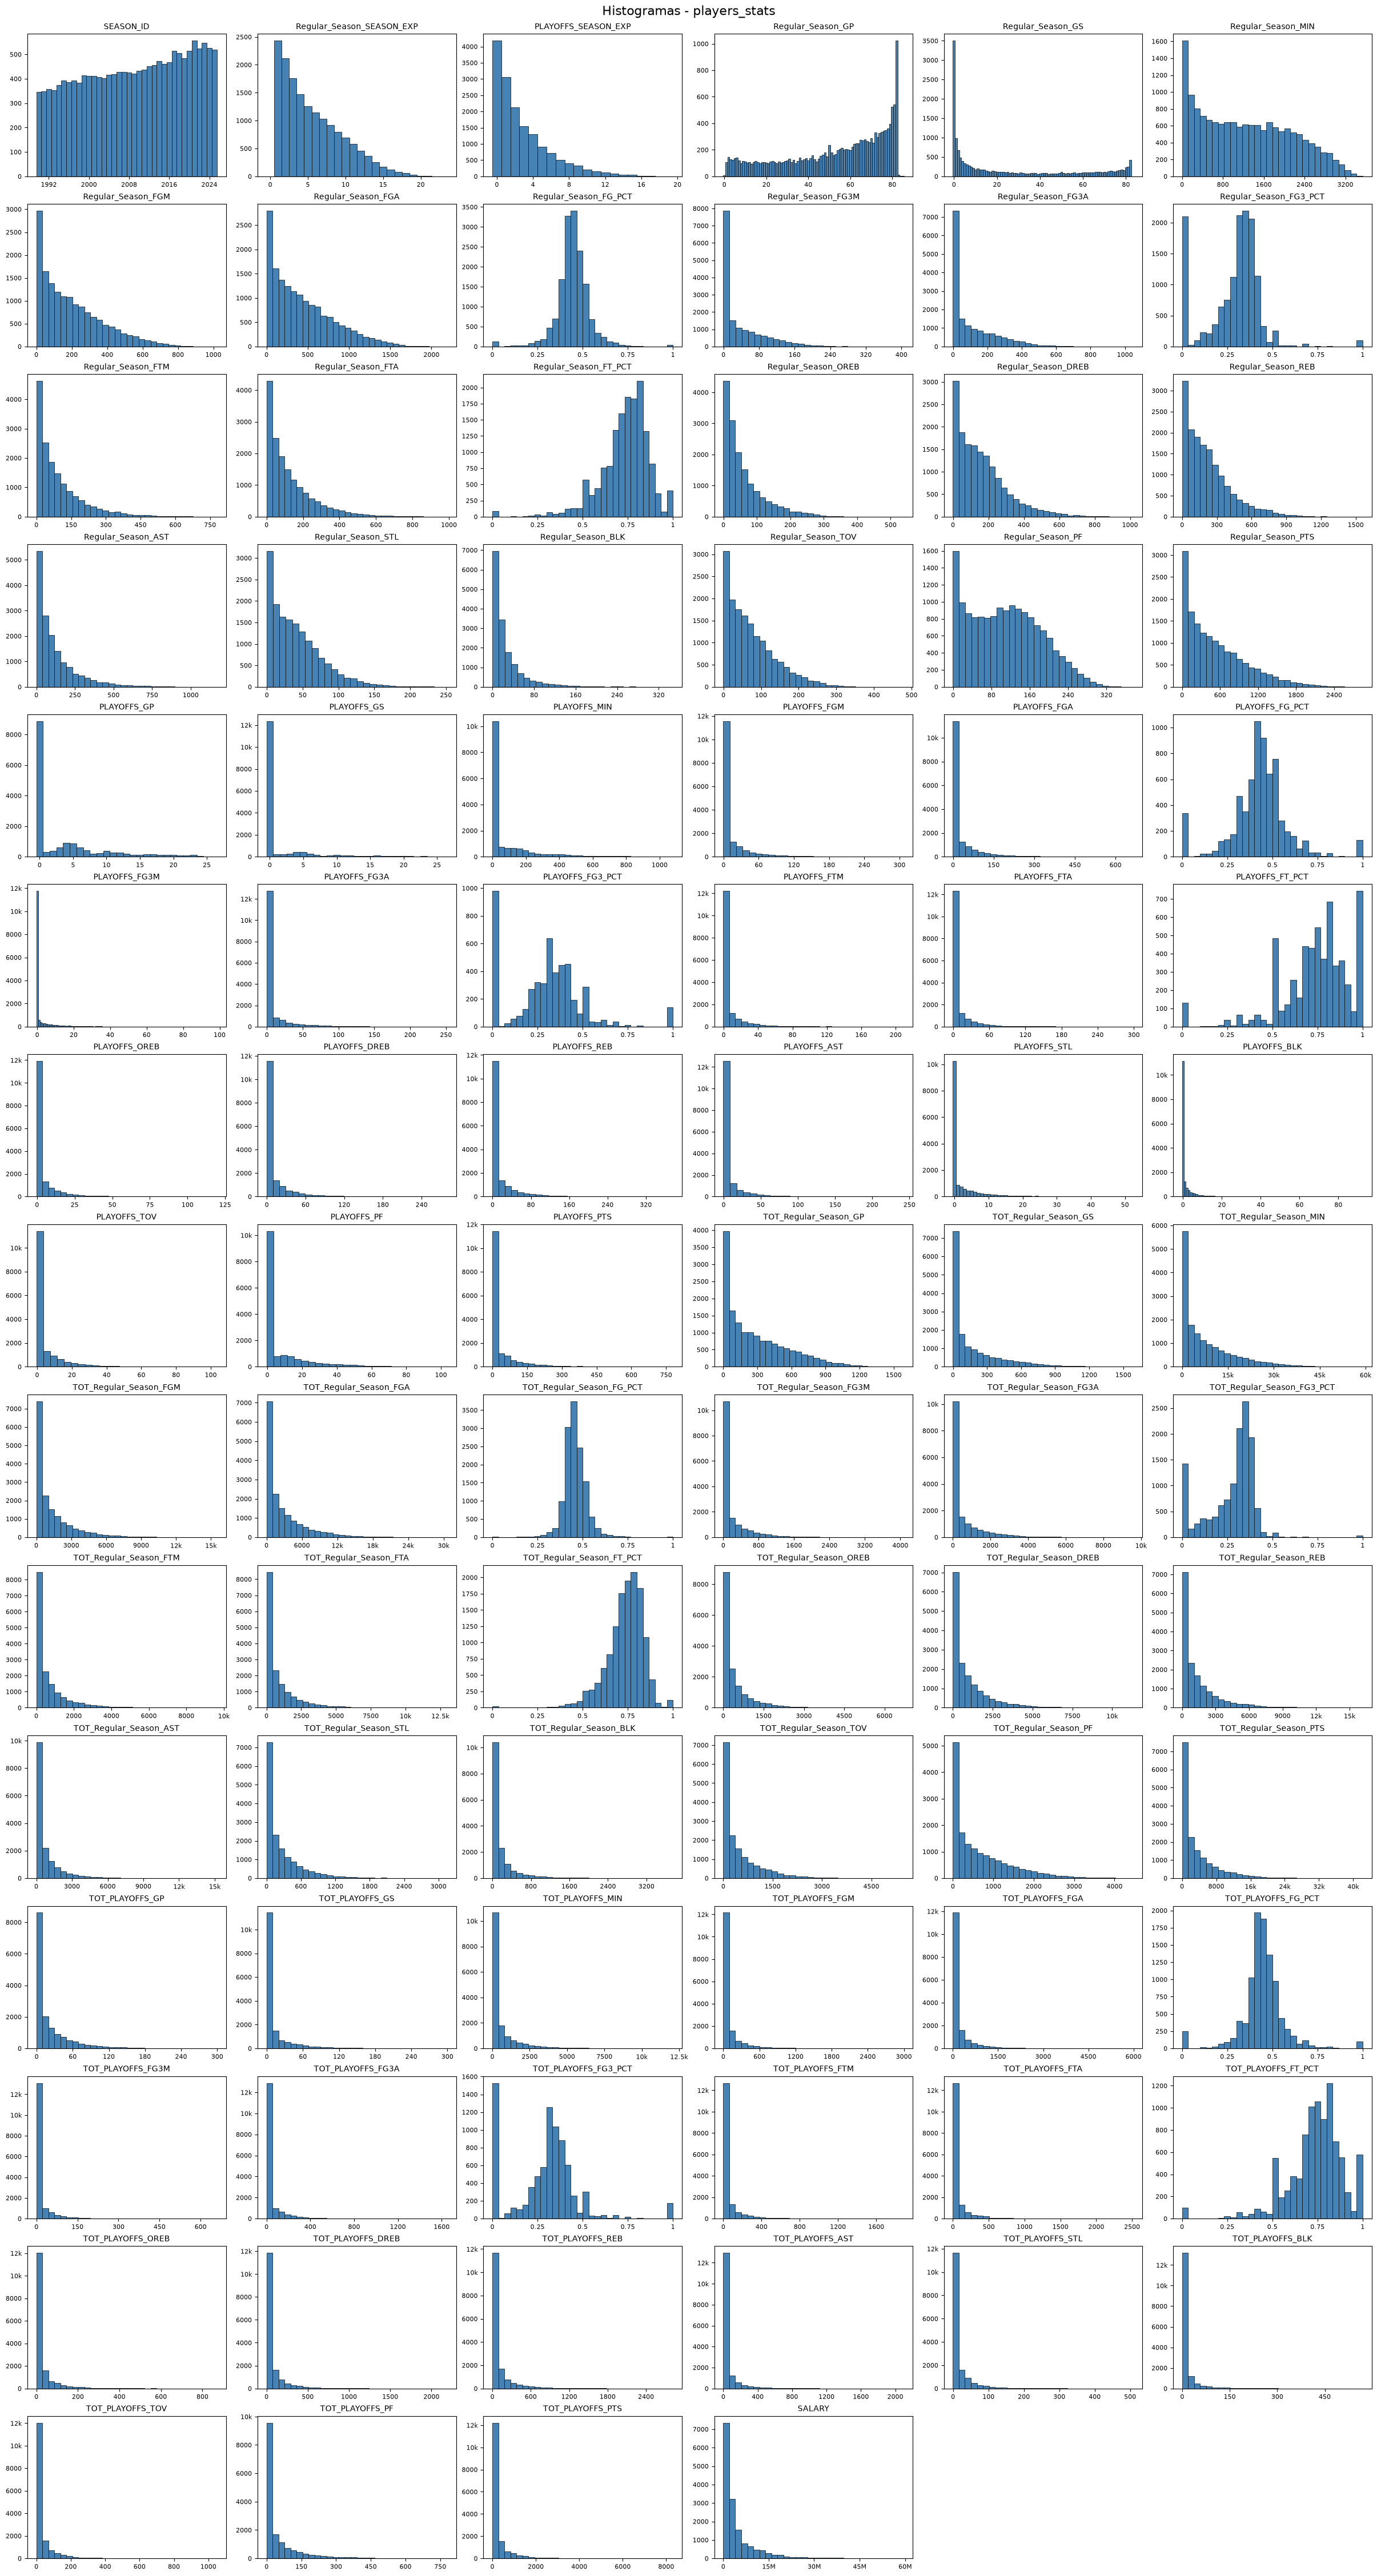

In [9]:
plt_histograms(players_stats,
               title="Histogramas - players_stats",
               colunas_irrelevantes=["PLAYER_ID"])

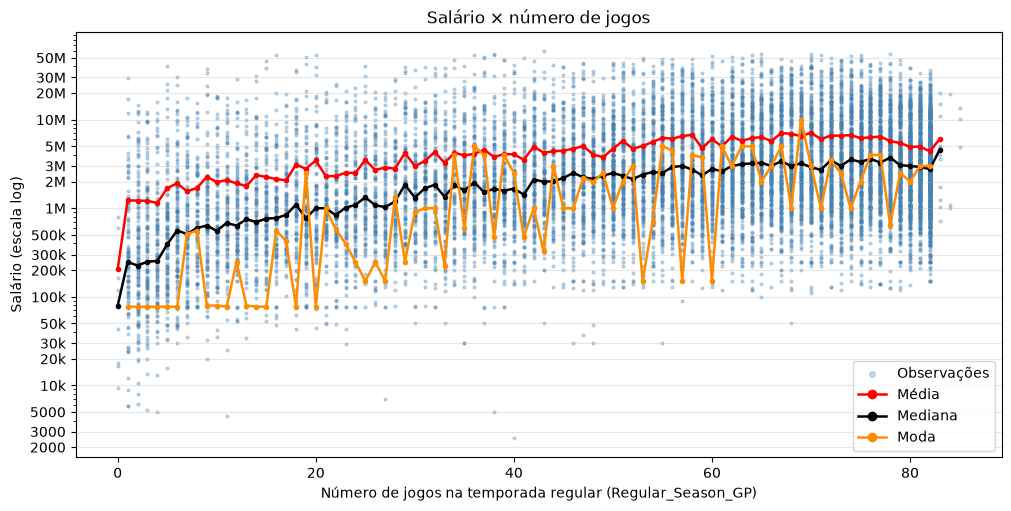

In [10]:
# x = número de jogos na temporada regular - y = salário
plt_scatter(players_stats,
            x="Regular_Season_GP",
            y="SALARY",
            title="Salário × número de jogos",
            xlabel="Número de jogos na temporada regular (Regular_Season_GP)",
            ylabel="Salário (escala log)")

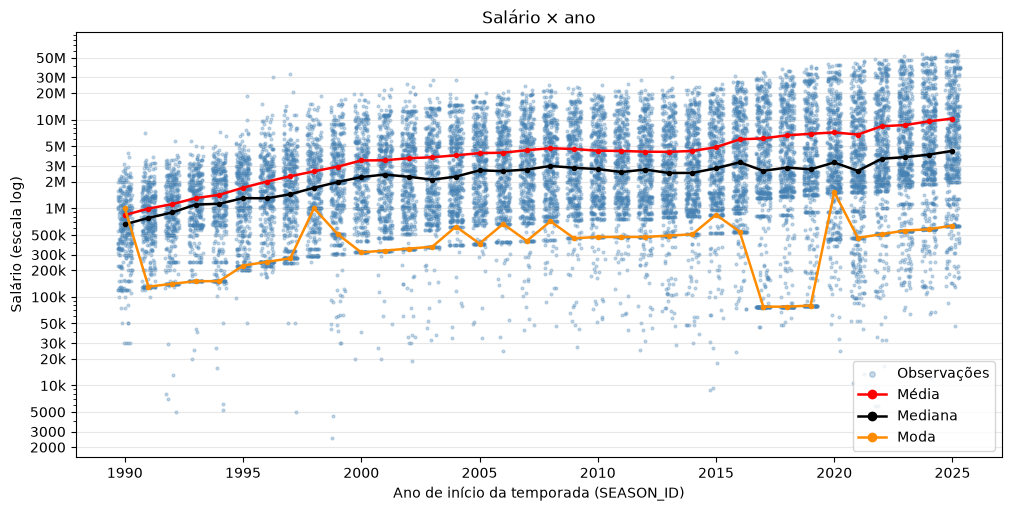

In [9]:
# x = ano de início da temporada - y = salário
plt_scatter(players_stats,
            x="SEASON_ID",
            y="SALARY",
            title="Salário × ano",
            xlabel="Ano de início da temporada (SEASON_ID)",
            ylabel="Salário (escala log)",
            jitter=0.3)   # SEASON_ID é inteiro: espalha os pontos de cada ano

### Salário: media x mediana x moda 

In [11]:
# media, mediana e moda de salario
salario_media = players_stats["SALARY"].mean()
salario_mediana = players_stats["SALARY"].median()
salario_moda = players_stats["SALARY"].mode()[0]

print("Média do salário:", salario_media)
print("Mediana do salário:", salario_mediana)
print("Moda do salário:", salario_moda)

Média do salário: 4779332.50548058
Mediana do salário: 2200000.0
Moda do salário: 1000000.0


### Definição da população

A exploração acima (histograma e média × mediana × moda do salário) mostra dois grupos de temporadas que não servem para comparar salário com desempenho:

- **Sem jogos na temporada regular** (`Regular_Season_GP == 0`): não há desempenho a avaliar.
- **Salário abaixo do mínimo da liga**: contratos parciais (10 dias, dispensas). O valor mede quanto tempo o jogador ficou contratado, não quanto o time acha que ele vale.

Esses filtros vêm **depois** da montagem: as temporadas saem do dataset, mas já contaram na experiência e nos acumulados de carreira (`TOT_*`) das temporadas seguintes.

In [12]:
SALARIO_MINIMO = 40_000
sem_jogos = players_stats["Regular_Season_GP"] == 0
salario_parcial = players_stats["SALARY"] < SALARIO_MINIMO

print("Sem jogos na temporada regular:", sem_jogos.sum())
print(f"Salário < {SALARIO_MINIMO:,}:", salario_parcial.sum())

players_stats = players_stats[~(sem_jogos | salario_parcial)].reset_index(drop=True)
print("players_stats:", players_stats.shape)

Sem jogos na temporada regular: 9
Salário < 40,000: 58
players_stats: (15719, 90)


---

## Divisão dos dados


1. **Alvo e divisão treino/teste**: `SALARY` (em dólares), com amostragem **estratificada** por faixa de salário
2. **Separar X e y**: só o conjunto de treino é usado daqui em diante.

> Tudo o que **aprende** com os dados (média, mediana, escala, categorias) é ajustado (`fit`) **só no treino**

In [13]:
# 1. Alvo e divisão treino/teste
from sklearn.model_selection import StratifiedGroupKFold

dados = players_stats.copy()   # população já filtrada no Tratamento de dados

# Alvo: SALARY (em dólares)

# Categoria de salário só para estratificar (papel do income_cat na a11)
dados["salario_cat"] = pd.qcut(dados["SALARY"], q=5, labels=False)

# 80/20 estratificado por salário E agrupado por jogador:
# todas as temporadas de um jogador ficam no mesmo conjunto → o modelo não "decora" o jogador
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
idx_treino, idx_teste = next(sgkf.split(dados, dados["salario_cat"], groups=dados["PLAYER_ID"]))

strat_train_set = dados.iloc[idx_treino].copy()
strat_test_set = dados.iloc[idx_teste].copy()

print("Treino:", strat_train_set.shape, "| Teste:", strat_test_set.shape)
print("Jogadores nos dois conjuntos:",
      len(set(strat_train_set["PLAYER_ID"]) & set(strat_test_set["PLAYER_ID"])))

# Conferindo a estratificação: proporção de cada faixa de salário
proporcoes = pd.DataFrame({"Geral": dados["salario_cat"].value_counts(normalize=True),
                           "Treino": strat_train_set["salario_cat"].value_counts(normalize=True),
                           "Teste": strat_test_set["salario_cat"].value_counts(normalize=True)}).sort_index()

for conjunto in (strat_train_set, strat_test_set):
    conjunto.drop(columns="salario_cat", inplace=True)

proporcoes.round(3)

Treino: (12576, 91) | Teste: (3143, 91)
Jogadores nos dois conjuntos: 0


,Geral,Treino,Teste
salario_cat,,,
0,0.2,0.2,0.2
1,0.2,0.2,0.2
2,0.2,0.2,0.2
3,0.2,0.2,0.2
4,0.2,0.2,0.2


In [14]:
# 2. Separar X (atributos) e y (rótulo) do conjunto de treino
NAO_ATRIBUTOS = ["PLAYER_ID", "SALARY"]

players = strat_train_set.drop(columns=NAO_ATRIBUTOS)   # X  (o "housing" da a11)
players_labels = strat_train_set["SALARY"].copy()        # y  (o "housing_labels" da a11)
players_groups = strat_train_set["PLAYER_ID"]           # grupos para a validação cruzada

players.shape, players_labels.shape

((12576, 88), (12576,))

### Transformadores personalizados para colunas

Classes do scikit-learn (`fit`/`transform`) que alteram as colunas antes do preparo padrão e entram dentro dos pipelines.

- **AtributosCombinados**: converte os totais em **médias por jogo**, cria a taxa de titular e indicadores (novato, fez playoffs, já jogou playoffs) e trata percentuais com poucas tentativas (n < 10).
- **AtributosMinimos**: mantém só `SEASON_ID`, `POSITION` e as estatísticas **mais correlacionadas com o salário**, calculadas apenas no treino.

In [15]:
# 3. Transformador personalizado (como o CombinedAttributesAdder da a11)
from sklearn.base import BaseEstimator, TransformerMixin


class AtributosCombinados(BaseEstimator, TransformerMixin):
    """
    Cria atributos derivados a partir das colunas de players_stats:
      - médias POR JOGO (temporada regular, playoffs e carreira antes da temporada)
        → o total depende de quantos jogos o jogador fez; a média mede qualidade
      - TAXA_TITULAR = GS / GP
      - indicadores dos zeros estruturais: NOVATO, FEZ_PLAYOFFS, JA_JOGOU_PLAYOFFS
        → o modelo passa a saber que aquele 0 significa "não jogou", e não "jogou mal"
      - percentuais com menos de `min_tentativas` tentativas viram NaN (1 de 1 = 100% não é confiável)

    Hiperparâmetros (podem ser testados no GridSearchCV, como o add_bedrooms_per_room do livro):
      remover_totais : descarta as contagens brutas depois de criar as médias
      min_tentativas : nº mínimo de tentativas para confiar em um percentual
    """

    PREFIXOS = ["Regular_Season_", "PLAYOFFS_", "TOT_Regular_Season_", "TOT_PLAYOFFS_"]
    CONTAGENS = ["MIN", "FGM", "FGA", "FG3M", "FG3A", "FTM", "FTA",
                 "OREB", "DREB", "REB", "AST", "STL", "BLK", "TOV", "PF", "PTS"]
    PERCENTUAIS = {"FG_PCT": "FGA", "FG3_PCT": "FG3A", "FT_PCT": "FTA"}

    def __init__(self, remover_totais=True, min_tentativas=10):
        self.remover_totais = remover_totais
        self.min_tentativas = min_tentativas

    def fit(self, X, y=None):
        return self  # nada a aprender

    def transform(self, X):
        X = X.copy()
        novas = {}

        for p in self.PREFIXOS:
            jogos = X[p + "GP"]
            jogou = jogos > 0
            for c in self.CONTAGENS:
                # sem jogos → 0 (o indicador abaixo diz ao modelo o que esse 0 significa)
                novas[p + c + "_POR_JOGO"] = (X[p + c] / jogos.where(jogou)).fillna(0)
            novas[p + "TAXA_TITULAR"] = (X[p + "GS"] / jogos.where(jogou)).fillna(0)

            # percentual pouco confiável → NaN (será imputado pela mediana no pipeline)
            for pct, tentados in self.PERCENTUAIS.items():
                X.loc[X[p + tentados] < self.min_tentativas, p + pct] = np.nan

        novas["NOVATO"] = (X["TOT_Regular_Season_GP"] == 0).astype(int)
        novas["FEZ_PLAYOFFS"] = (X["PLAYOFFS_GP"] > 0).astype(int)
        novas["JA_JOGOU_PLAYOFFS"] = (X["TOT_PLAYOFFS_GP"] > 0).astype(int)

        X = pd.concat([X, pd.DataFrame(novas, index=X.index)], axis=1)

        if self.remover_totais:
            X = X.drop(columns=[p + c for p in self.PREFIXOS for c in self.CONTAGENS + ["GS"]])
        return X


players_extra_attribs = AtributosCombinados().transform(players)
print(players.shape, "→", players_extra_attribs.shape)
players_extra_attribs[["NOVATO", "FEZ_PLAYOFFS", "JA_JOGOU_PLAYOFFS",
                       "Regular_Season_PTS_POR_JOGO", "Regular_Season_MIN_POR_JOGO"]].describe().round(2)

(12576, 88) → (12576, 91)


,NOVATO,FEZ_PLAYOFFS,JA_JOGOU_PLAYOFFS,Regular_Season_PTS_POR_JOGO,Regular_Season_MIN_POR_JOGO
count,12576.00,12576.00,12576.00,12576.00,12576.00
mean,0.15,0.44,0.64,8.62,20.75
std,0.36,0.50,0.48,6.13,9.98
min,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,3.90,12.46
50%,0.00,0.00,1.00,7.12,20.28
75%,0.00,1.00,1.00,12.06,29.16
max,1.00,1.00,1.00,36.13,43.73


In [16]:
# 3. Transformador de seleção mínima de atributos (usado no pipeline_min_features)
class AtributosMinimos(BaseEstimator, TransformerMixin):
    """
    Mantém só SEASON_ID, POSITION e as estatísticas mais correlacionadas com o salário em cada bloco:
      n_regular  → do bloco Regular_Season_*                      (temporada atual)
      n_playoffs → do bloco PLAYOFFS_*                            (temporada atual)
      n_tot      → dos blocos TOT_Regular_Season_* e TOT_PLAYOFFS_* (carreira antes da temporada)

    A correlação (|Pearson| com o SALARY) é calculada no fit → só com os dados de treino.
    Dentro do Grid Search ela é recalculada em cada fold: a validação nunca influencia a escolha.
    """

    FIXAS = ["SEASON_ID", "POSITION"]
    BLOCOS = {"n_regular":  ("Regular_Season_",),
              "n_playoffs": ("PLAYOFFS_",),
              "n_tot":      ("TOT_Regular_Season_", "TOT_PLAYOFFS_")}

    def __init__(self, n_regular=3, n_playoffs=3, n_tot=2):
        self.n_regular = n_regular
        self.n_playoffs = n_playoffs
        self.n_tot = n_tot

    def fit(self, X, y):
        alvo = pd.Series(np.asarray(y), index=X.index)
        correlacao = X.select_dtypes("number").corrwith(alvo).abs()

        self.selecionadas_ = {}
        for parametro, prefixos in self.BLOCOS.items():
            do_bloco = [c for c in correlacao.index if c.startswith(prefixos)]
            self.selecionadas_[parametro] = correlacao[do_bloco].nlargest(getattr(self, parametro)).index.tolist()

        self.colunas_ = self.FIXAS + [c for cols in self.selecionadas_.values() for c in cols]
        self.correlacao_ = correlacao[self.colunas_[len(self.FIXAS):]]   # para consulta
        return self

    def transform(self, X):
        return X[self.colunas_].copy()

    def get_feature_names_out(self, input_features=None):
        return np.array(self.colunas_, dtype=object)


minimos = AtributosMinimos().fit(players, players_labels)
print(players.shape, "→", minimos.transform(players).shape)
minimos.correlacao_.round(3).to_frame("|correlação| com SALARY")

(12576, 88) → (12576, 10)


,|correlação| com SALARY
Regular_Season_PTS,0.469
Regular_Season_FGM,0.457
Regular_Season_FGA,0.441
PLAYOFFS_SEASON_EXP,0.356
PLAYOFFS_PTS,0.340
PLAYOFFS_FGM,0.337
TOT_Regular_Season_PTS,0.514
TOT_Regular_Season_FG3A,0.510


### Criação dos pipelines:

Foram testados 4 pipelines para comparar **quais atributos** ajudam mais a prever o salário. O modelo é o mesmo; muda só o que entra nele.

Todos terminam no mesmo preparo: numéricos → mediana + padronização; `POSITION` → one-hot.

- **`pipeline_main`**: atributos originais, sem nenhuma alteração.
- **`pipeline_atbcmb1`**: troca os totais por **médias por jogo** e adiciona indicadores (novato, fez playoffs, taxa de titular).
- **`pipeline_atbcmb2`**: igual ao anterior, mas **mantém também os totais** junto com as médias.
- **`pipeline_min_features`**: só `SEASON_ID`, `POSITION` e as 8 estatísticas mais correlacionadas com o salário. Feito para trabalhar com **poucas colunas** e permitir o polinômio de grau 3.

In [17]:
# 4. Pipelines de transformação (numérico + categórico → ColumnTransformer)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import clone

num_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")),   # mediana: robusta à assimetria
                         ("scaler", StandardScaler())])                   # necessário p/ Ridge, Lasso, SGD

cat_pipeline = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
                         ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])



pipeline_main = ColumnTransformer([("num_pipeline", num_pipeline, make_column_selector(dtype_include=np.number)),
                             ("cat_pipeline", cat_pipeline, ["POSITION"])])

pipeline_atbcmb1 = Pipeline([("atributos", AtributosCombinados()),
                            ("preparo", clone(pipeline_main))])

pipeline_atbcmb2 = Pipeline([("atributos", AtributosCombinados(remover_totais=False)),
                            ("preparo", clone(pipeline_main))])

# Só SEASON_ID, POSITION e as 3 + 3 + 2 estatísticas mais correlacionadas com o salário (célula 3b)
# → ~16 colunas preparadas: leve o bastante para o polinômio de grau 3
pipeline_min_features = Pipeline([("atributos", AtributosMinimos(n_regular=3, n_playoffs=3, n_tot=2)),
                                  ("preparo", clone(pipeline_main))])


players_prepared_main = pipeline_main.fit_transform(players)

players_prepared_atbc1 = pipeline_atbcmb1.fit_transform(players)   # fit SÓ no treino

players_prepared_atbc2 = pipeline_atbcmb2.fit_transform(players)   # fit SÓ no treino

players_prepared_min = pipeline_min_features.fit_transform(players, players_labels)   # y: a seleção usa a correlação


nomes_atributos = pipeline_main.get_feature_names_out()
print(players_prepared_main.shape)
print("NaN restantes:", np.isnan(players_prepared_main).sum())
pd.DataFrame(players_prepared_main, columns=nomes_atributos, index=players.index).head()

(12576, 95)
NaN restantes: 0


,num_pipeline__SEASON_ID,num_pipeline__Regular_Season_SEASON_EXP,num_pipeline__PLAYOFFS_SEASON_EXP,num_pipeline__Regular_Season_GP,num_pipeline__Regular_Season_GS,num_pipeline__Regular_Season_MIN,num_pipeline__Regular_Season_FGM,num_pipeline__Regular_Season_FGA,num_pipeline__Regular_Season_FG_PCT,num_pipeline__Regular_Season_FG3M,...,num_pipeline__TOT_PLAYOFFS_PF,num_pipeline__TOT_PLAYOFFS_PTS,cat_pipeline__POSITION_Center,cat_pipeline__POSITION_Center-Forward,cat_pipeline__POSITION_Forward,cat_pipeline__POSITION_Forward-Center,cat_pipeline__POSITION_Forward-Guard,cat_pipeline__POSITION_Guard,cat_pipeline__POSITION_Guard-Forward,cat_pipeline__POSITION_missing
0,-1.812414,0.593797,1.660378,1.181487,1.919161,1.531156,1.699187,1.637742,0.370343,0.635328,...,2.678966,2.849827,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,-1.715349,0.840749,1.981505,1.181487,1.919161,1.586139,1.466864,1.514728,0.158132,0.299206,...,3.245427,3.287673,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-1.618284,1.087701,2.302631,0.184827,0.918885,0.461786,0.537572,0.589453,0.057611,0.101488,...,3.352306,3.426232,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,-1.521220,1.334653,2.623758,0.558574,-0.840219,-0.076826,0.310915,0.292616,0.258653,-0.234633,...,3.469873,3.551859,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,-1.424155,1.581606,2.944884,1.098432,-0.874711,0.294592,0.361913,0.386214,0.124625,0.793502,...,3.705008,3.782790,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


### Montagem e explicação do grid search

- **Modelos testados:** Regressão Linear, Ridge, Elastic Net, Árvore de Decisão e Floresta Aleatória.

- **Graus do polinômio** (só nos modelos de regressão): 1, 2 e 3. O grau 3 foi usado apenas no `pipeline_min_features` e sem o Elastic Net.

- **Função de erro:** RMSE (raiz do erro quadrático médio), em dólares:

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(y_i - \hat{y}_i\right)^2}$$


In [19]:
# 5. Grid Search: um para CADA pipeline de pré-processamento, com validação cruzada (estratificada + agrupada por jogador)
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
import re
import hashlib
import joblib
from pathlib import Path

# Divisões da validação cruzada: estratificadas por faixa de salário e agrupadas por jogador.
# MESMAS para todos os pipelines.
faixas_treino = pd.qcut(players_labels, q=5, labels=False)
cv = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
          .split(players, faixas_treino, groups=players_groups))


# ------------------------ grade de modelos (igual para todos os pipelines)
RIDGE_ALPHA   = {"modelo__alpha": [1, 10, 100, 1000, 10000, 100000]}
ELASTIC_ALPHA = {"modelo__alpha": [0.001, 0.01, 0.1, 1]}


# Regressão polinomial para os modelos de regressão:
POLY = [PolynomialFeatures(include_bias=False)]
GRAU_1 = {"poly": POLY, "poly__degree": [1]}
GRAU_2 = {"poly": POLY, "poly__degree": [2], "scaler_poly": [StandardScaler()]}    # padroniza os termos novos
GRAU_3 = {"poly": POLY, "poly__degree": [3], "scaler_poly": [StandardScaler()]}

# Modelos
LINEAR  = {"modelo": [LinearRegression()]}
RIDGE   = {**RIDGE_ALPHA, "modelo": [Ridge()]}
ELASTIC = {**ELASTIC_ALPHA, "modelo": [ElasticNet(max_iter=5000, precompute=True)], "modelo__l1_ratio": [0.2, 0.5, 0.8]}
MODELOS_REGRESSAO = [LINEAR, RIDGE, ELASTIC]
ARVORE = {"modelo": [DecisionTreeRegressor(random_state=42)],
          "modelo__max_depth": [5, 10, None],
          "modelo__min_samples_leaf": [1, 10]}
FLORESTA = {"modelo": [RandomForestRegressor(n_estimators=100, random_state=42)],
            "modelo__max_features": [0.3, 0.6],
            "modelo__min_samples_leaf": [1, 5]}



def montar_grade(graus):
    """Cada modelo de regressão com cada grau + árvore e floresta (sem polinômio)."""
    grade = []
    for grau in graus:
        for modelo in MODELOS_REGRESSAO:
            if grau is GRAU_3 and modelo is ELASTIC:
                continue   # Elastic Net grau 3: ~11 min por treino (medido) × 150 treinos → fica de fora
            grade.append({**grau, **modelo})
    return grade + [ARVORE, FLORESTA]


# ------------------------ pipelines (célula 4) e os graus que cada um aguenta
# n_jobs = treinos em paralelo. 
N_JOBS = 3
PIPELINES = {
    "pipeline_main":         {"prep": pipeline_main,         "graus": [GRAU_1, GRAU_2],         "n_jobs": N_JOBS},
    "pipeline_atbcmb1":      {"prep": pipeline_atbcmb1,      "graus": [GRAU_1, GRAU_2],         "n_jobs": N_JOBS},
    "pipeline_atbcmb2":      {"prep": pipeline_atbcmb2,      "graus": [GRAU_1],                 "n_jobs": 6},  # com totais: grau 2 ≈ 13 mil colunas → sem memória
    "pipeline_min_features": {"prep": pipeline_min_features, "graus": [GRAU_1, GRAU_2, GRAU_3], "n_jobs": 6},  # 17 colunas → grau 3 = 1.139 colunas
}


# ---------------------- salva um arquivo por pipeline
def _impressao_digital(*objetos):
    """Hash do conteúdo: muda se qualquer valor/linha mudar."""
    h = hashlib.md5()
    for obj in objetos:
        h.update(pd.util.hash_pandas_object(obj, index=True).values.tobytes())
    return h.hexdigest()


DADOS = _impressao_digital(players, players_labels, players_groups)


def treinar_ou_carregar(nome, pipe, grade, n_jobs):
    """Carrega modelos/grid_search_<nome>.joblib se pipeline, grade e dados forem os mesmos; senão treina e salva."""
    arquivo = Path(f"modelos/grid_search_{nome}.joblib")
    chave = {"pipeline": re.sub(r" at 0x[0-9A-Fa-f]+", "", repr(pipe)),   # tira o endereço de memória (muda a cada execução)
             "grade": repr(grade),
             "dados": DADOS}
    salvo = joblib.load(arquivo) if arquivo.exists() else None
    if salvo is not None and salvo["chave"] == chave:
        print(f"{nome}: CARREGADO de {arquivo} (treinado em {salvo['treinado_em']})")
        return salvo["grid"]

    grid = GridSearchCV(pipe, grade, cv=cv,
                        scoring="neg_root_mean_squared_error",   # RMSE em US$ (negativo: o GridSearchCV maximiza)
                        refit=True,                              # retreina a melhor combinação com todo o treino
                        n_jobs=n_jobs,
                        return_train_score=True)                 # erro de treino → tabela treino × validação
    inicio = pd.Timestamp.now()
    grid.fit(players, players_labels)   # executa o Grid Search (demorado)
    arquivo.parent.mkdir(exist_ok=True)
    joblib.dump({"chave": chave, "grid": grid, "treinado_em": inicio.strftime("%d/%m/%Y %H:%M")}, arquivo, compress=3)
    print(f"{nome}: TREINADO em {(pd.Timestamp.now() - inicio).total_seconds() / 60:.1f} min e salvo em {arquivo}")
    return grid


def organizar(grid, nome):
    """cv_results_ → uma linha por combinação, com nomes legíveis e erros em US$."""
    r = pd.DataFrame(grid.cv_results_)
    r["Pipeline"] = nome
    r["indice_grid"] = r.index   # posição no cv_results_ deste grid (para comparar com grid.best_index_)
    r["Modelo"] = r["params"].map(
        lambda p: type(p["modelo"]).__name__ + (f" + Polinômio grau {p['poly__degree']}" if "poly__degree" in p else ""))
    r["Hiperparâmetros"] = r["params"].map(
        lambda p: {k.split("__")[-1]: v for k, v in p.items() if k not in ("modelo", "poly", "scaler_poly")})
    r["RMSE treino (US$)"] = -r["mean_train_score"]
    r["RMSE validação (US$)"] = -r["mean_test_score"]
    r["Diferença (US$)"] = r["RMSE validação (US$)"] - r["RMSE treino (US$)"]   # maior = mais sobreajuste
    r["Desvio validação (US$)"] = r["std_test_score"]                           # variação entre os 5 folds
    return r


# ---------------------------------------------------------------- um Grid Search por pipeline
grids = {}
for nome, cfg in PIPELINES.items():
    pipe = Pipeline([("prep", clone(cfg["prep"])),
                     ("poly", "passthrough"),          # quadrados e produtos (ligado pela grade)
                     ("scaler_poly", "passthrough"),   # padroniza os termos novos (ligado pela grade)
                     ("modelo", LinearRegression())])  # lugar reservado: a grade troca o modelo
    grids[nome] = treinar_ou_carregar(nome, pipe, montar_grade(cfg["graus"]), cfg["n_jobs"])


# Resultados de todos os pipelines juntos, do menor erro de validação para o maior
resultados = (pd.concat([organizar(g, nome) for nome, g in grids.items()], ignore_index=True)
              .sort_values("RMSE validação (US$)"))

# O melhor modelo geral (menor erro de validação entre TODOS os pipelines)
melhor = resultados.iloc[0]
grid = grids[melhor["Pipeline"]]   # grid do pipeline vencedor: grid.best_estimator_ = melhor modelo geral
print()
print("Melhor pipeline: ", melhor["Pipeline"])
print("Melhor modelo:   ", melhor["Modelo"])
print("Hiperparâmetros: ", melhor["Hiperparâmetros"])
print(f"RMSE treino:      {melhor['RMSE treino (US$)']:.0f}")
print(f"RMSE validação:   {melhor['RMSE validação (US$)']:.0f}  (desvio entre os folds: {melhor['Desvio validação (US$)']:.0f})")
print(f"Diferença:        {melhor['Diferença (US$)']:.0f}")

# Melhor configuração de cada modelo em cada pipeline, do menor erro de validação para o maior
COLUNAS_ERRO = ["RMSE treino (US$)", "RMSE validação (US$)", "Diferença (US$)", "Desvio validação (US$)"]
pd.set_option("display.max_colwidth", None)
tabela_modelos = (resultados.groupby(["Pipeline", "Modelo"]).head(1)
                  [["Pipeline", "Modelo", "Hiperparâmetros"] + COLUNAS_ERRO].reset_index(drop=True))
tabela_modelos.style.format("{:.0f}", subset=COLUNAS_ERRO)   # números brutos, sem casas decimais

pipeline_main: CARREGADO de modelos\grid_search_pipeline_main.joblib (treinado em 15/11/2026 21:37)
pipeline_atbcmb1: CARREGADO de modelos\grid_search_pipeline_atbcmb1.joblib (treinado em 15/11/2026 23:27)
pipeline_atbcmb2: CARREGADO de modelos\grid_search_pipeline_atbcmb2.joblib (treinado em 16/11/2026 01:15)
pipeline_min_features: CARREGADO de modelos\grid_search_pipeline_min_features.joblib (treinado em 16/11/2026 01:18)

Melhor pipeline:  pipeline_atbcmb1
Melhor modelo:    RandomForestRegressor
Hiperparâmetros:  {'max_features': 0.6, 'min_samples_leaf': 1}
RMSE treino:      939186
RMSE validação:   2971584  (desvio entre os folds: 202553)
Diferença:        2032398


,Pipeline,Modelo,Hiperparâmetros,RMSE treino (US$),RMSE validação (US$),Diferença (US$),Desvio validação (US$)
0,pipeline_atbcmb1,RandomForestRegressor,"{'max_features': 0.6, 'min_samples_leaf': 1}",939186,2971584,2032398,202553
1,pipeline_atbcmb2,RandomForestRegressor,"{'max_features': 0.6, 'min_samples_leaf': 5}",1507612,2996423,1488811,196558
2,pipeline_main,RandomForestRegressor,"{'max_features': 0.6, 'min_samples_leaf': 5}",1770028,3221686,1451659,160752
3,pipeline_atbcmb1,ElasticNet + Polinômio grau 2,"{'alpha': 1, 'l1_ratio': 0.8, 'degree': 2}",2666987,3357746,690758,174636
4,pipeline_atbcmb1,Ridge + Polinômio grau 2,"{'alpha': 1000, 'degree': 2}",2554367,3406539,852173,173854
5,pipeline_main,ElasticNet + Polinômio grau 2,"{'alpha': 1, 'l1_ratio': 0.8, 'degree': 2}",2828057,3478912,650855,214672
6,pipeline_main,Ridge + Polinômio grau 2,"{'alpha': 1000, 'degree': 2}",2710703,3518113,807409,199441
7,pipeline_min_features,RandomForestRegressor,"{'max_features': 0.6, 'min_samples_leaf': 5}",2468345,3662361,1194016,216016
8,pipeline_atbcmb1,DecisionTreeRegressor,"{'max_depth': 10, 'min_samples_leaf': 10}",2218954,3667515,1448561,251625
9,pipeline_atbcmb2,DecisionTreeRegressor,"{'max_depth': 10, 'min_samples_leaf': 10}",2171015,3670397,1499382,257766


### Curvas de aprendizado dos 11 modelos com menor erro

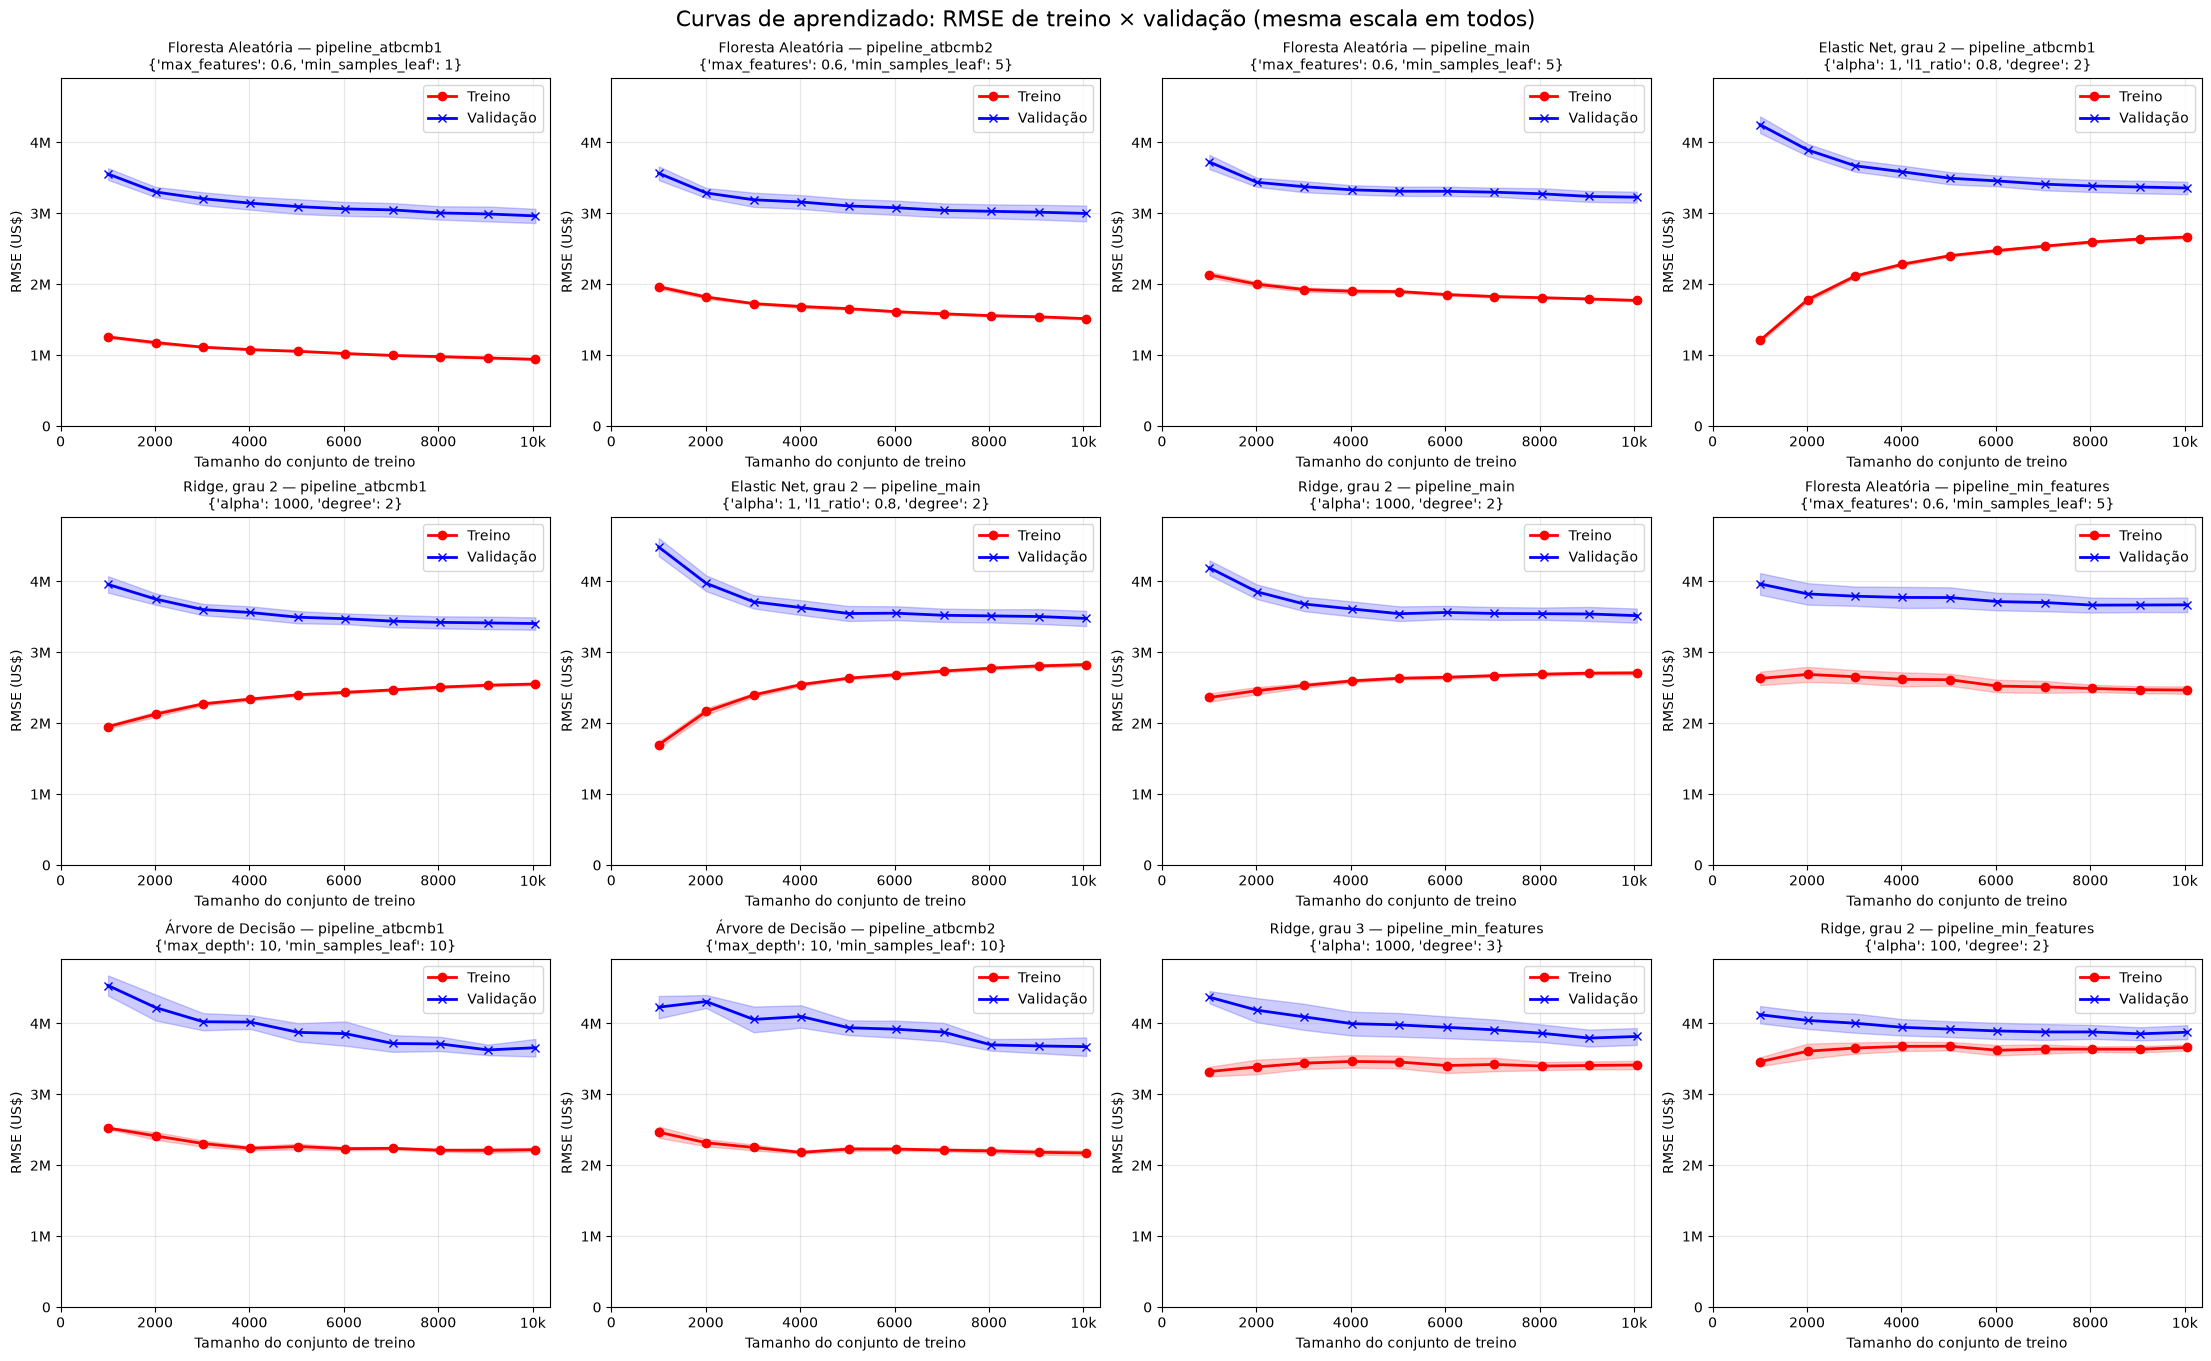

In [ ]:
# 7. Curvas de aprendizado (a13) dos modelos escolhidos para comparação

from sklearn.base import clone

# (título do gráfico, pipeline, nome na coluna "Modelo") → usa a MELHOR configuração desse modelo nesse pipeline
CURVAS = [
    ("Floresta Aleatória",        "pipeline_atbcmb1",      "RandomForestRegressor"),          # max_features=0.6, min_samples_leaf=1 (melhor modelo)
    ("Floresta Aleatória",        "pipeline_atbcmb2",      "RandomForestRegressor"),          # max_features=0.6, min_samples_leaf=5
    ("Floresta Aleatória",        "pipeline_main",         "RandomForestRegressor"),          # max_features=0.6, min_samples_leaf=5
    ("Elastic Net, grau 2",       "pipeline_atbcmb1",      "ElasticNet + Polinômio grau 2"),  # alpha=1, l1_ratio=0.8
    ("Ridge, grau 2",             "pipeline_atbcmb1",      "Ridge + Polinômio grau 2"),       # alpha=1000
    ("Elastic Net, grau 2",       "pipeline_main",         "ElasticNet + Polinômio grau 2"),  # alpha=1, l1_ratio=0.8
    ("Ridge, grau 2",             "pipeline_main",         "Ridge + Polinômio grau 2"),       # alpha=1000
    ("Floresta Aleatória",        "pipeline_min_features", "RandomForestRegressor"),          # max_features=0.6, min_samples_leaf=5
    ("Árvore de Decisão",         "pipeline_atbcmb1",      "DecisionTreeRegressor"),          # max_depth=10, min_samples_leaf=10
    ("Árvore de Decisão",         "pipeline_atbcmb2",      "DecisionTreeRegressor"),          # max_depth=10, min_samples_leaf=10
    ("Ridge, grau 3",             "pipeline_min_features", "Ridge + Polinômio grau 3"),       # alpha=1000
    ("Ridge, grau 2",             "pipeline_min_features", "Ridge + Polinômio grau 2"),       # alpha=100
]

# Grade de gráficos numa única figura (como o plt_histograms)
n_cols = 4
n_linhas = int(np.ceil(len(CURVAS) / n_cols))
fig, axes = plt.subplots(n_linhas, n_cols, figsize=(5.5 * n_cols, 4.5 * n_linhas), layout="constrained", squeeze=False)
axes = axes.flatten()

maior_x, maior_y = 0, 0   # todos os gráficos na mesma escala

for ax, (titulo, pipeline, nome_modelo) in zip(axes, CURVAS):
    linhas = resultados[(resultados["Pipeline"] == pipeline) & (resultados["Modelo"] == nome_modelo)]
    escolhido = linhas.iloc[0]   # `resultados` está ordenado pelo RMSE de validação

    modelo = clone(grids[pipeline].estimator).set_params(**escolhido["params"])   # pipeline completo com esses hiperparâmetros
    tamanhos, erros_treino, erros_validacao = plt_learning_curve(modelo, players, players_labels,
                       cv=cv,           # mesmas divisões do Grid Search (estratificadas e agrupadas por jogador)
                       n_jobs=N_JOBS,   
                       ax=ax,
                       title=f"{titulo} — {pipeline}\n{escolhido['Hiperparâmetros']}")

    # maior valor desenhado neste gráfico (média + erro padrão, como na faixa sombreada)
    for erros in (erros_treino, erros_validacao):
        erro_padrao = erros.std(axis=1, ddof=1) / np.sqrt(erros.shape[1])
        maior_y = max(maior_y, (erros.mean(axis=1) + erro_padrao).max())
    maior_x = max(maior_x, tamanhos.max())

# Mesma escala em todos: x de 0 ao maior tamanho de treino; y de 0 ao maior erro entre todos os modelos
for ax in axes[:len(CURVAS)]:
    ax.set_xlim(0, maior_x * 1.03)
    ax.set_ylim(0, maior_y * 1.05)
    ax.legend(loc="upper right")

# desliga os eixos que sobraram na grade
for ax in axes[len(CURVAS):]:
    ax.axis("off")

fig.suptitle("Curvas de aprendizado: RMSE de treino × validação (mesma escala em todos)", fontsize=16)
plt.show()

### explicação da escolha do modelo.

**Modelo escolhido:**

```
Melhor pipeline:  pipeline_atbcmb1
Melhor modelo:    ElasticNet - grau 2
Hiperparâmetros:  {'alpha': 1, 'l1_ratio': 0.8, 'degree': 2}
RMSE treino:      2666987
RMSE validação:   3357746  (desvio entre os folds: 174636)
Diferença:        690758
```

- A Floresta Aleatória teve o menor erro de validação (2,97 M), mas está sobreajustada: erro de treino muito abaixo do de validação.
- Os modelos lineares de grau 1 quase não têm sobreajuste, mas erram muito (acima de 4 M): estão subajustados.
- O Elastic Net tem um bom equilíbrio entre suas métricas de erro de treino e erro de validação, e suas curvas de aprendizado ainda estão convergindo.

---

### Teste final com o conjunto de teste: strat_test_set

In [20]:
# 8. Avaliação no conjunto de teste: modelo escolhido
# O conjunto de teste: (strat_test_set, separado desde o início)
from sklearn.base import clone
from sklearn.metrics import root_mean_squared_error

PIPELINE_ESCOLHIDO = "pipeline_atbcmb1"
MODELO_ESCOLHIDO   = "ElasticNet + Polinômio grau 2"

X_teste = strat_test_set.drop(columns=NAO_ATRIBUTOS)
y_teste = strat_test_set["SALARY"].copy()

# melhor configuração desse modelo nesse pipeline (`resultados` está ordenado pelo RMSE de validação)
escolhido = resultados[(resultados["Pipeline"] == PIPELINE_ESCOLHIDO) &
                       (resultados["Modelo"] == MODELO_ESCOLHIDO)].iloc[0]

# retreina com TODO o conjunto de treino, como o refit do Grid Search faria
modelo_final = clone(grids[PIPELINE_ESCOLHIDO].estimator).set_params(**escolhido["params"])
modelo_final.fit(players, players_labels)

rmse_teste = root_mean_squared_error(y_teste, modelo_final.predict(X_teste))

print(f"Pipeline:         {escolhido['Pipeline']}")
print(f"Modelo:           {escolhido['Modelo']}")
print(f"Hiperparâmetros:  {escolhido['Hiperparâmetros']}")
print(f"RMSE treino:      {escolhido['RMSE treino (US$)']:.0f}")
print(f"RMSE validação:   {escolhido['RMSE validação (US$)']:.0f}  (desvio entre os folds: {escolhido['Desvio validação (US$)']:.0f})")
print(f"RMSE teste:       {rmse_teste:.0f}")
print(f"Teste − validação: {rmse_teste - escolhido['RMSE validação (US$)']:.0f}")

Pipeline:         pipeline_atbcmb1
Modelo:           ElasticNet + Polinômio grau 2
Hiperparâmetros:  {'alpha': 1, 'l1_ratio': 0.8, 'degree': 2}
RMSE treino:      2666987
RMSE validação:   3357746  (desvio entre os folds: 174636)
RMSE teste:       3576376
Teste − validação: 218630


---

---

### Seleção dos jogadores mais super-faturados

In [ ]:
# 9. Seleção dos superfaturados

# Usar o modelo escolhido (modelo_final, célula 8) para prever o salário de TODAS as temporadas (base inteira, sem dividir)
X_todos = dados.drop(columns=NAO_ATRIBUTOS + ["salario_cat"], errors="ignore")
previsto = modelo_final.predict(X_todos)

nomes = pd.read_csv("nba/players_bio.csv", usecols=["PERSON_ID", "DISPLAY_FIRST_LAST"]) \
          .rename(columns={"PERSON_ID": "PLAYER_ID", "DISPLAY_FIRST_LAST": "JOGADOR"})

avaliacao = dados[["PLAYER_ID", "SEASON_ID", "SALARY"]].copy()
avaliacao["PREVISTO"] = previsto
avaliacao["RESIDUO"] = avaliacao["SALARY"] - avaliacao["PREVISTO"]       # real − previsto (> 0: ganha mais que o previsto)
avaliacao = avaliacao.merge(nomes, on="PLAYER_ID", how="left")

# Medida estatística: z-score do resíduo POR FAIXA de salário previsto
LIMIAR_Z = 2   # superfaturado: resíduo mais de 2 desvios acima do erro típico da sua faixa

avaliacao["FAIXA"] = pd.qcut(avaliacao["PREVISTO"], q=10)
por_faixa = avaliacao.groupby("FAIXA", observed=True)["RESIDUO"]
avaliacao["Z"] = (avaliacao["RESIDUO"] - por_faixa.transform("mean")) / por_faixa.transform("std")
avaliacao["SUPERFATURADO"] = avaliacao["Z"] > LIMIAR_Z

# Ranking: as 20 temporadas mais superfaturadas (maior z)
(avaliacao.sort_values("Z", ascending=False).head(20)
    [["JOGADOR", "SEASON_ID", "SALARY", "PREVISTO", "RESIDUO", "Z"]]
    .rename(columns={"JOGADOR": "Jogador", "SEASON_ID": "Temporada", "SALARY": "Salário real",
                     "PREVISTO": "Salário previsto", "RESIDUO": "Resíduo"})
    .round({"Salário previsto": 0, "Resíduo": 0, "Z": 2})
    .reset_index(drop=True))

,Jogador,Temporada,Salário real,Salário previsto,Resíduo,Z
0,Jalen Rose,2006,16141500.0,2577983.0,13563517.0,9.28
1,Allen Crabbe,2016,18500000.0,3449153.0,15050847.0,8.21
2,John Stockton,2002,7875000.0,999563.0,6875437.0,7.65
3,Reed Sheppard,2024,10098960.0,1770880.0,8328080.0,7.19
4,Tim Thomas,2000,8510000.0,1041000.0,7469000.0,6.98
5,Tidjane Salaün,2025,7863240.0,1239779.0,6623461.0,6.19
6,John Stockton,2000,11000000.0,2606366.0,8393634.0,5.81
7,Alan Williams,2017,6000000.0,857873.0,5142127.0,5.66
8,Troy Hudson,2007,7172590.0,1205158.0,5967432.0,5.57
9,Kobe Bufkin,2025,5612215.0,564435.0,5047780.0,5.56
